In [49]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

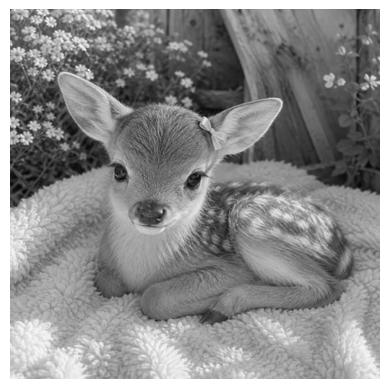

In [51]:
image = cv2.imread('img1.jpg', cv2.IMREAD_GRAYSCALE)
h, w = image.shape
s = min(h, w)
image = cv2.resize(image[(h-s)//2:(h+s)//2, (w-s)//2:(w+s)//2], (512, 512))
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

In [52]:
def haar(image, levels):
    c = image.astype(np.float32)
    for l in range(levels):
        n = c.shape[0] >> l
        b = c[:n, :n]
        b = np.hstack(((b[:, 0::2] + b[:, 1::2]) / 2,
                       (b[:, 0::2] - b[:, 1::2]) / 2))
        c[:n, :n] = np.vstack(((b[0::2] + b[1::2]) / 2,
                               (b[0::2] - b[1::2]) / 2))
    return c


def ihaar(coef, levels):
    c = coef.copy()
    for l in range(levels - 1, -1, -1):
        n = c.shape[0] >> l
        k = n // 2
        b = c[:n, :n]
        t = np.empty_like(b)
        t[0::2], t[1::2] = b[:k] + b[k:], b[:k] - b[k:]
        c[:n, :n][:, 0::2], c[:n, :n][:, 1::2] = (
            t[:, :k] + t[:, k:],
            t[:, :k] - t[:, k:]
        )
    return c

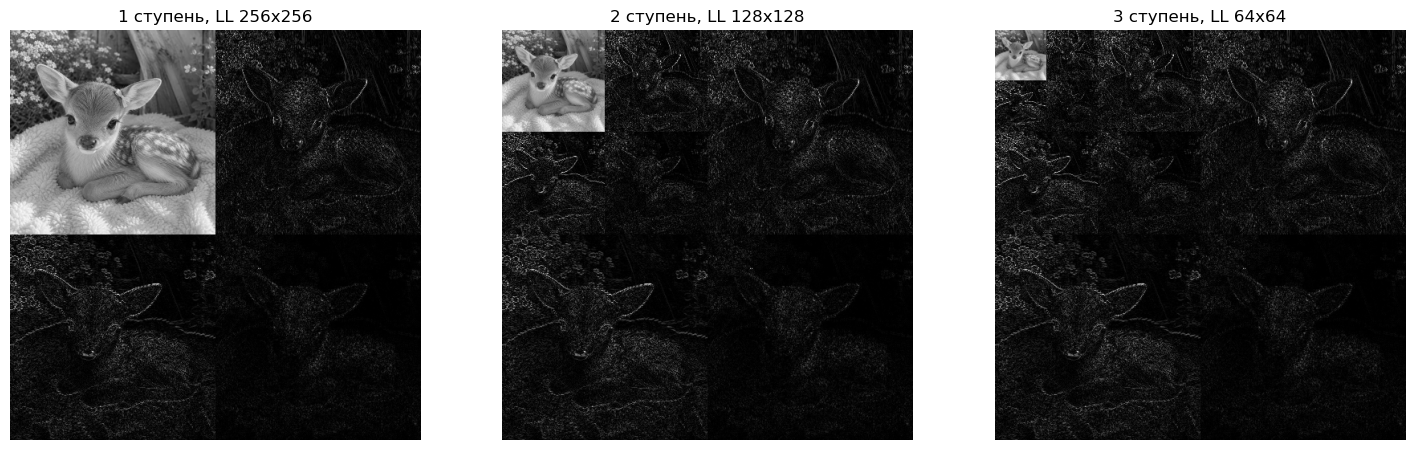

In [53]:
plt.figure(figsize=(18, 6))
for l in range(1, 4):
    c = haar(image, l)
    vis = np.clip(np.abs(c) * 5, 0, 255)
    n = 512 >> l
    vis[:n, :n] = c[:n, :n]
    plt.subplot(1, 3, l)
    plt.imshow(vis, cmap='gray')
    plt.title(f'{l} ступень, LL {n}x{n}')
    plt.axis('off')
plt.show()

In [54]:
rec = ihaar(haar(image, 3), 3)
print('max error:', np.max(np.abs(image - rec)))

max error: 0.0
